In [1]:
# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the cleaned dataset from Task 1
df = pd.read_csv("../Task-1-Data-Cleaning/cleaned_online_retail.csv")

# Display the first five rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ZeroPriceFlag,NegativePriceFlag,NegativeQuantityFlag,Revenue,HighQuantityFlag
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,False,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,False,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,20.34,False


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (536641, 13)


In [4]:
# Check the column names and data types
print("Column names and data types:")
print(df.dtypes)

# Check summary statistics for numerical columns
print("\nSummary statistics:")
display(df.describe())

Column names and data types:
InvoiceNo                object
StockCode                object
Description              object
Quantity                  int64
InvoiceDate              object
UnitPrice               float64
CustomerID              float64
Country                  object
ZeroPriceFlag              bool
NegativePriceFlag          bool
NegativeQuantityFlag       bool
Revenue                 float64
HighQuantityFlag           bool
dtype: object

Summary statistics:


,Quantity,UnitPrice,CustomerID,Revenue
count,536641.000000,536641.000000,401604.000000,536641.000000
mean,9.620029,4.632656,15281.160818,18.123861
std,219.130156,97.233118,1714.006089,380.656263
min,-80995.000000,-11062.060000,12346.000000,-168469.600000
25%,1.000000,1.250000,13939.000000,3.750000
50%,3.000000,2.080000,15145.000000,9.870000
75%,10.000000,4.130000,16784.000000,17.400000
max,80995.000000,38970.000000,18287.000000,168469.600000


In [5]:
# Convert invoice dates into datetime format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Convert customer IDs into nullable integers
df["CustomerID"] = df["CustomerID"].astype("Int64")

# Check the updated data types
print(df[["InvoiceDate", "CustomerID"]].dtypes)

# Display the first five rows again
display(df.head())

InvoiceDate    datetime64[ns]
CustomerID              Int64
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ZeroPriceFlag,NegativePriceFlag,NegativeQuantityFlag,Revenue,HighQuantityFlag
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,False,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,False,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,20.34,False


In [6]:
# Check the date range
print("First transaction date:", df["InvoiceDate"].min())
print("Last transaction date:", df["InvoiceDate"].max())

# Count unique invoices
print("Unique invoices:", df["InvoiceNo"].nunique())

# Count unique customers, excluding missing IDs
print("Unique customers:", df["CustomerID"].nunique())

# Count unique products by stock code
print("Unique products:", df["StockCode"].nunique())

# Count unique countries
print("Unique countries:", df["Country"].nunique())

First transaction date: 2010-12-01 08:26:00
Last transaction date: 2011-12-09 12:50:00
Unique invoices: 25900
Unique customers: 4372
Unique products: 4070
Unique countries: 38


In [7]:
# Check missing values in each column
print("Missing values by column:")
print(df.isnull().sum())

# Check how many rows have each unusual transaction flag
print("\nZero-price rows:", df["ZeroPriceFlag"].sum())
print("Negative-price rows:", df["NegativePriceFlag"].sum())
print("Negative-quantity rows:", df["NegativeQuantityFlag"].sum())
print("High-quantity rows:", df["HighQuantityFlag"].sum())

# Check cancellation invoices
cancellations = df["InvoiceNo"].astype(str).str.startswith("C")
print("Cancellation invoice rows:", cancellations.sum())

Missing values by column:
InvoiceNo                    0
StockCode                    0
Description               1509
Quantity                     0
InvoiceDate                  0
UnitPrice                    0
CustomerID              135037
Country                      0
ZeroPriceFlag                0
NegativePriceFlag            0
NegativeQuantityFlag         0
Revenue                      0
HighQuantityFlag             0
dtype: int64

Zero-price rows: 2510
Negative-price rows: 2
Negative-quantity rows: 10587
High-quantity rows: 172
Cancellation invoice rows: 9251


In [8]:
# Extract the month from each invoice date
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Calculate total net revenue for each month
monthly_revenue = (
    df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

# Display the monthly revenue
display(monthly_revenue)

,YearMonth,Revenue
0,2010-12,746723.610
1,2011-01,558448.560
2,2011-02,497026.410
3,2011-03,682013.980
4,2011-04,492367.841
5,2011-05,722094.100
6,2011-06,689977.230
7,2011-07,680156.991
8,2011-08,681386.460
9,2011-09,1017596.682


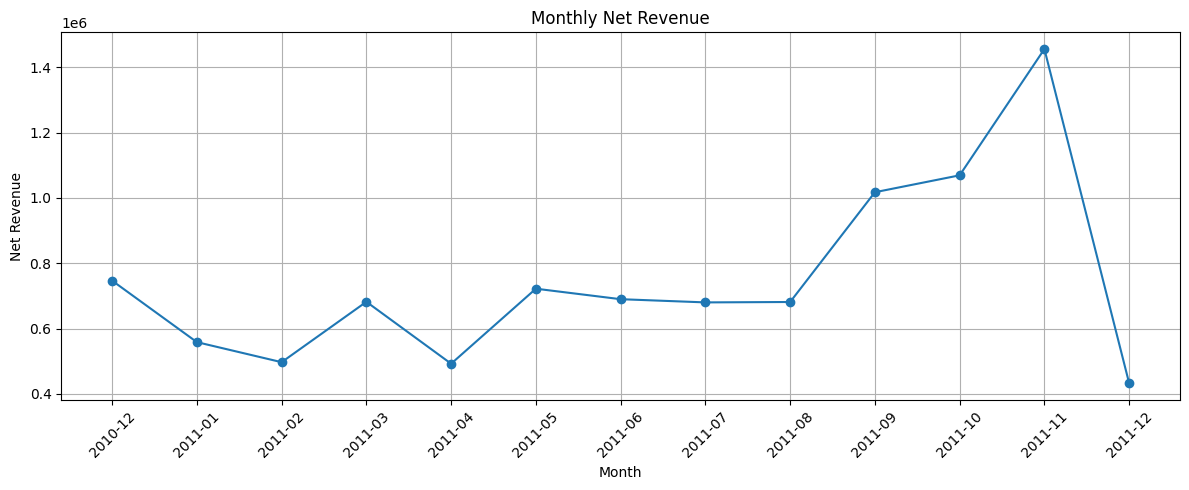

In [9]:
# Convert YearMonth to strings for chart labels
monthly_revenue["YearMonth"] = monthly_revenue["YearMonth"].astype(str)

# Create a line chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Net Revenue")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

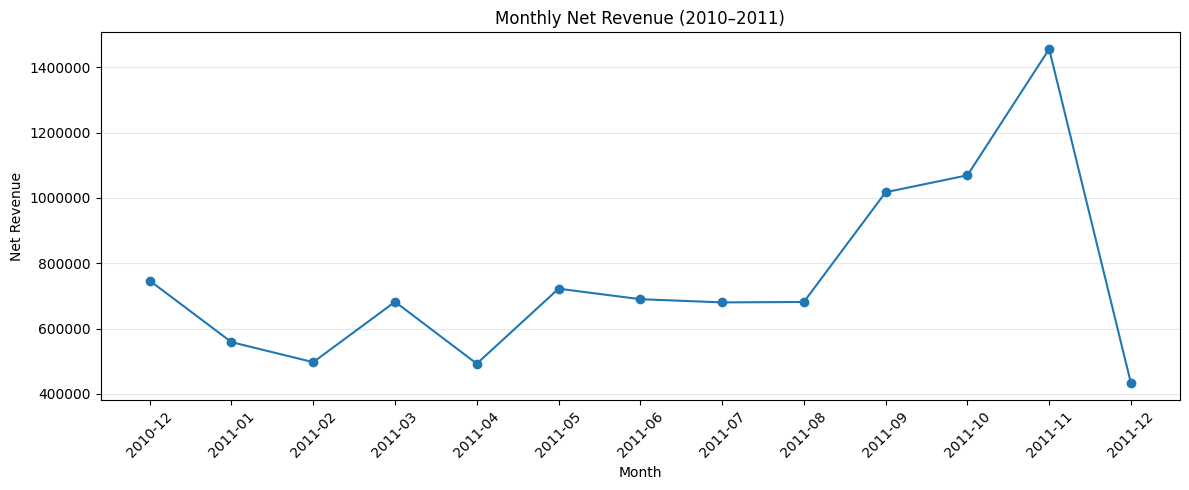

In [10]:
# Create a cleaner monthly revenue chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Net Revenue (2010–2011)")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(rotation=45)

# Display revenue values in a readable format
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Calculate net revenue for each country
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Display the top 10 countries
display(country_revenue.head(10))

,Country,Revenue
0,United Kingdom,8167128.184
1,Netherlands,284661.540
2,EIRE,262993.380
3,Germany,221509.470
4,France,197317.110
5,Australia,137009.770
6,Switzerland,56363.050
7,Spain,54756.030
8,Belgium,40910.960
9,Sweden,36585.410


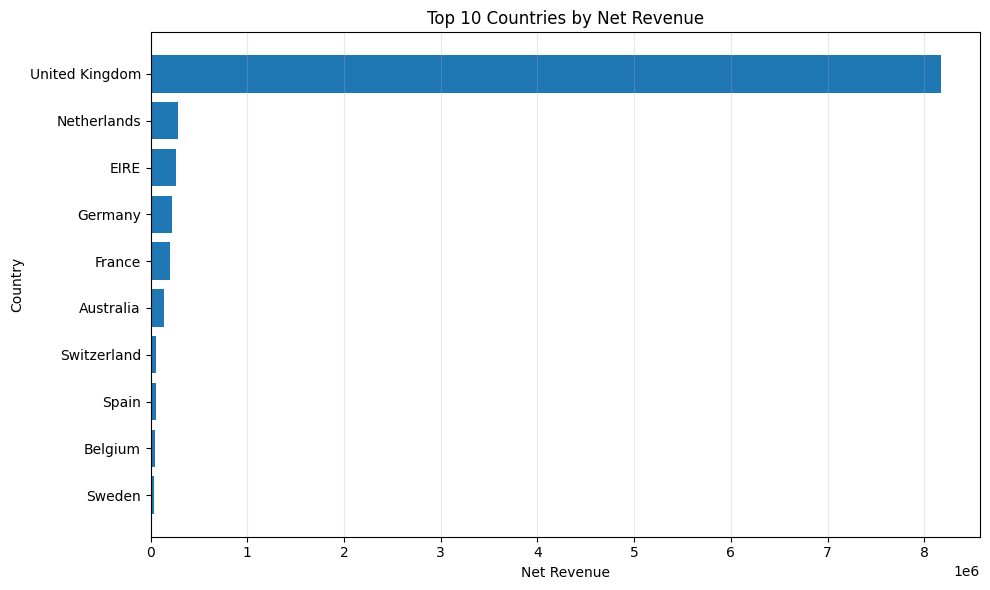

In [12]:
# Select the top 10 countries by net revenue
top_10_countries = country_revenue.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_countries["Country"][::-1],
    top_10_countries["Revenue"][::-1]
)

plt.title("Top 10 Countries by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Calculate total net revenue across all countries
total_revenue = df["Revenue"].sum()

# Get net revenue for the United Kingdom
uk_revenue = country_revenue.loc[
    country_revenue["Country"] == "United Kingdom",
    "Revenue"
].iloc[0]

# Calculate the UK's percentage of total net revenue
uk_percentage = (uk_revenue / total_revenue) * 100

print(f"Total net revenue: {total_revenue:,.2f}")
print(f"UK net revenue: {uk_revenue:,.2f}")
print(f"UK share of total net revenue: {uk_percentage:.2f}%")

Total net revenue: 9,726,006.95
UK net revenue: 8,167,128.18
UK share of total net revenue: 83.97%


In [14]:
# Group transactions by product code
product_revenue = (
    df.groupby("StockCode")
    .agg(
        Net_Revenue=("Revenue", "sum"),
        Net_Quantity=("Quantity", "sum"),
        Description=("Description", "first")
    )
    .sort_values("Net_Revenue", ascending=False)
    .reset_index()
)

# Display the top 10 products by net revenue
display(product_revenue.head(10))

,StockCode,Net_Revenue,Net_Quantity,Description
0,DOT,206245.48,1707,DOTCOM POSTAGE
1,22423,164459.49,12954,REGENCY CAKESTAND 3 TIER
2,47566,98243.88,18010,PARTY BUNTING
3,85123A,97838.45,38811,WHITE HANGING HEART T-LIGHT HOLDER
4,85099B,92175.79,47260,JUMBO BAG RED RETROSPOT
5,23084,66661.63,30597,RABBIT NIGHT LIGHT
6,POST,66230.64,6353,POSTAGE
7,22086,63715.24,18876,PAPER CHAIN KIT 50'S CHRISTMAS
8,84879,58792.42,36122,ASSORTED COLOUR BIRD ORNAMENT
9,79321,53746.66,10339,CHILLI LIGHTS


In [15]:
# Exclude postage-related stock codes for merchandise analysis
merchandise = product_revenue[
    ~product_revenue["StockCode"].isin(["DOT", "POST"])
]

# Show the top 10 merchandise items by net revenue
top_10_merchandise = merchandise.head(10)

display(top_10_merchandise)

,StockCode,Net_Revenue,Net_Quantity,Description
1,22423,164459.49,12954,REGENCY CAKESTAND 3 TIER
2,47566,98243.88,18010,PARTY BUNTING
3,85123A,97838.45,38811,WHITE HANGING HEART T-LIGHT HOLDER
4,85099B,92175.79,47260,JUMBO BAG RED RETROSPOT
5,23084,66661.63,30597,RABBIT NIGHT LIGHT
7,22086,63715.24,18876,PAPER CHAIN KIT 50'S CHRISTMAS
8,84879,58792.42,36122,ASSORTED COLOUR BIRD ORNAMENT
9,79321,53746.66,10339,CHILLI LIGHTS
10,22502,51023.52,1870,PICNIC BASKET WICKER SMALL
11,22197,50967.92,56427,SMALL POPCORN HOLDER


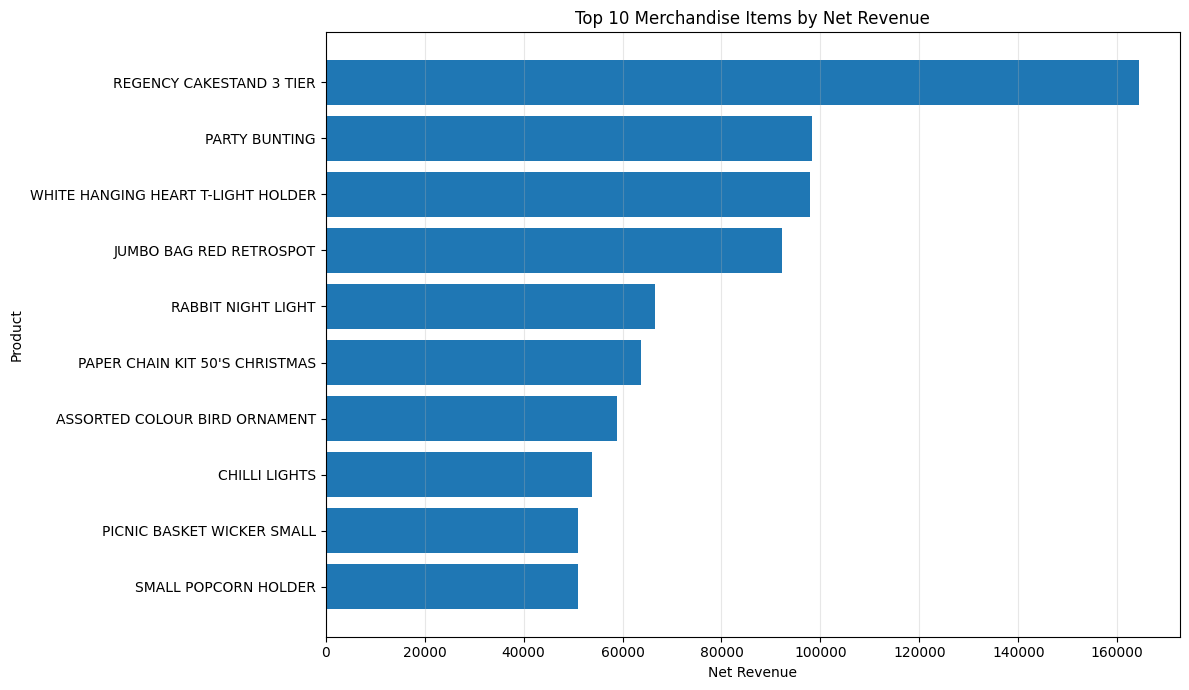

In [16]:
# Create a horizontal bar chart of top merchandise items
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_merchandise["Description"][::-1],
    top_10_merchandise["Net_Revenue"][::-1]
)

plt.title("Top 10 Merchandise Items by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("Product")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Extract the day of the week from each invoice date
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()

# Set the correct weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Calculate net revenue for each day
weekday_revenue = (
    df.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(weekday_order)
    .reset_index()
)

# Display the results
display(weekday_revenue)


,DayOfWeek,Revenue
0,Monday,1584895.301
1,Tuesday,1965703.611
2,Wednesday,1730088.430
3,Thursday,2108701.530
4,Friday,1537958.621
5,Saturday,NaN
6,Sunday,798659.461


In [18]:
# Count transaction rows for each day of the week
weekday_counts = (
    df["DayOfWeek"]
    .value_counts()
    .reindex(weekday_order, fill_value=0)
)

print("Transaction rows by weekday:")
print(weekday_counts)

Transaction rows by weekday:
DayOfWeek
Monday        94435
Tuesday      101064
Wednesday     93715
Thursday     103056
Friday        81565
Saturday          0
Sunday        62806
Name: count, dtype: int64


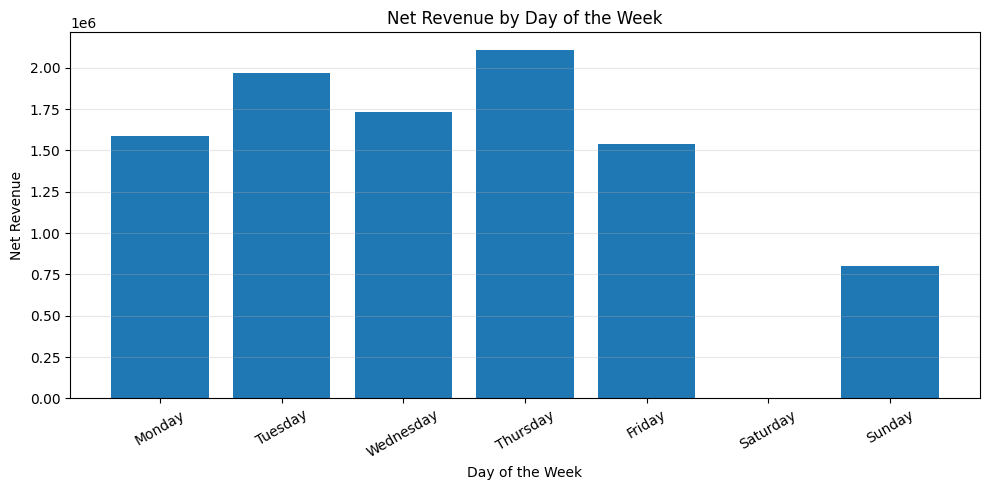

In [19]:
# Plot net revenue by weekday
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_revenue["DayOfWeek"],
    weekday_revenue["Revenue"]
)

plt.title("Net Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Net Revenue")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Calculate net quantity for each product
product_quantity = (
    df.groupby("StockCode")
    .agg(
        Net_Quantity=("Quantity", "sum"),
        Description=("Description", "first")
    )
    .sort_values("Net_Quantity", ascending=False)
    .reset_index()
)

# Exclude postage-related stock codes
product_quantity = product_quantity[
    ~product_quantity["StockCode"].isin(["DOT", "POST"])
]

# Display the top 10 products by net quantity
display(product_quantity.head(10))

,StockCode,Net_Quantity,Description
0,22197,56427,SMALL POPCORN HOLDER
1,84077,53751,WORLD WAR 2 GLIDERS ASSTD DESIGNS
2,85099B,47260,JUMBO BAG RED RETROSPOT
3,85123A,38811,WHITE HANGING HEART T-LIGHT HOLDER
4,84879,36122,ASSORTED COLOUR BIRD ORNAMENT
5,21212,36016,PACK OF 72 RETROSPOT CAKE CASES
6,23084,30597,RABBIT NIGHT LIGHT
7,22492,26437,MINI PAINT SET VINTAGE
8,22616,26299,PACK OF 12 LONDON TISSUES
9,21977,24719,PACK OF 60 PINK PAISLEY CAKE CASES


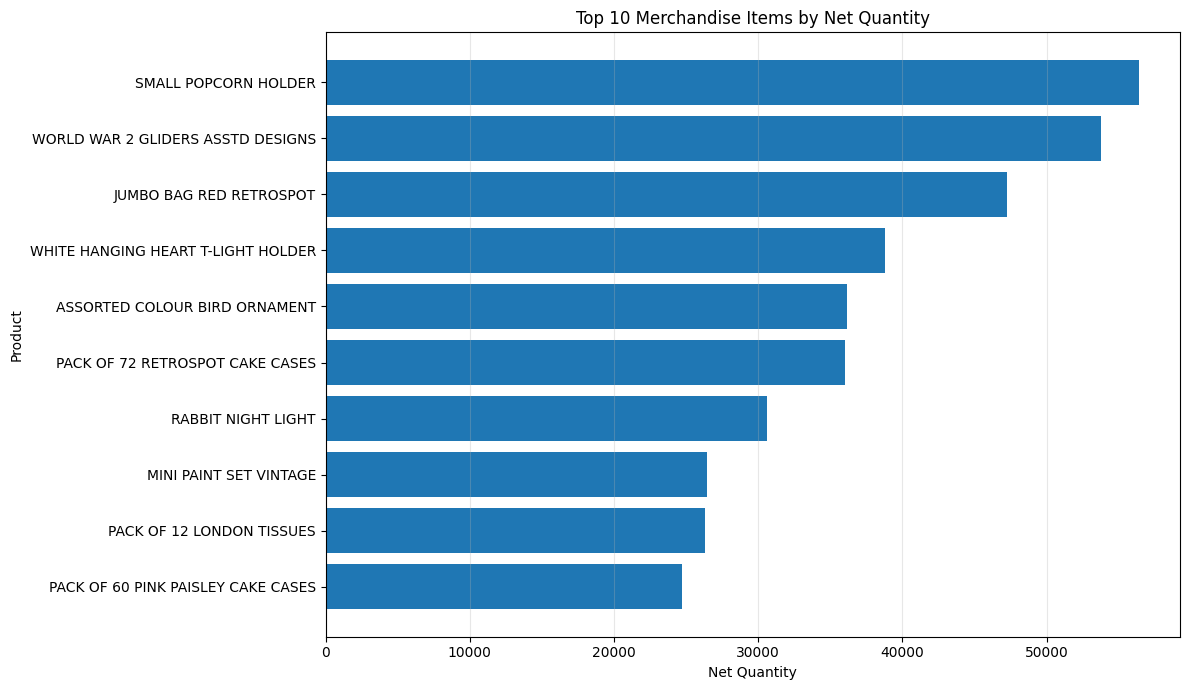

In [21]:
# Select the top 10 products by net quantity
top_10_quantity = product_quantity.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_quantity["Description"][::-1],
    top_10_quantity["Net_Quantity"][::-1]
)

plt.title("Top 10 Merchandise Items by Net Quantity")
plt.xlabel("Net Quantity")
plt.ylabel("Product")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Calculate net revenue for each identifiable customer
customer_revenue = (
    df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Net_Revenue=("Revenue", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .sort_values("Net_Revenue", ascending=False)
    .reset_index()
)

# Display the top 10 customers
display(customer_revenue.head(10))

,CustomerID,Net_Revenue,Invoice_Count
0,14646,279489.02,77
1,18102,256438.49,62
2,17450,187322.17,55
3,14911,132458.73,248
4,12415,123725.45,26
5,14156,113214.59,66
6,17511,88125.38,46
7,16684,65892.08,31
8,13694,62690.54,60
9,15311,59284.19,118


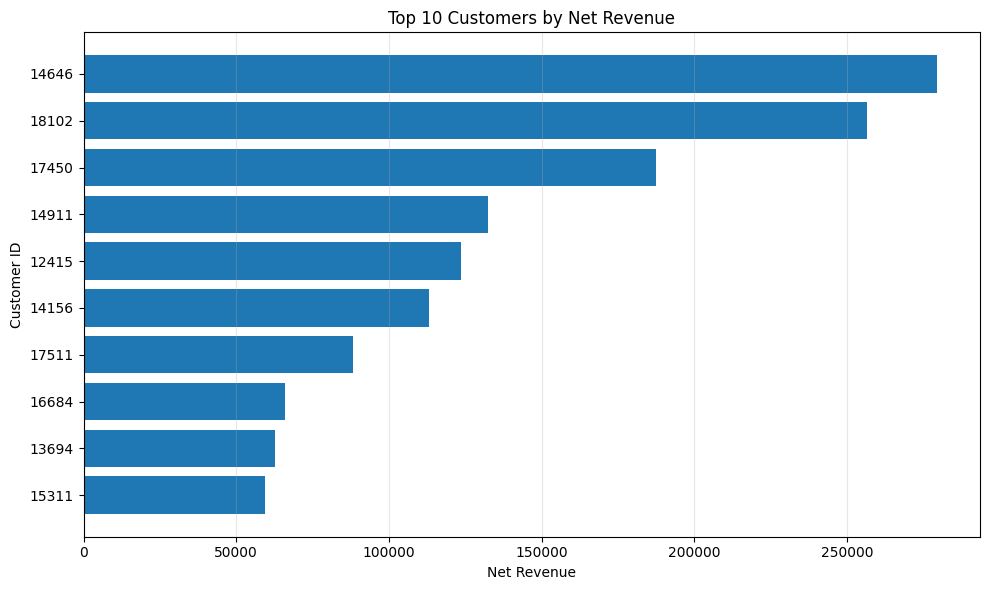

In [23]:
# Select the top 10 customers by net revenue
top_10_customers = customer_revenue.head(10).copy()

# Convert customer IDs to strings for chart labels
top_10_customers["CustomerID"] = (
    top_10_customers["CustomerID"].astype(str)
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_customers["CustomerID"][::-1],
    top_10_customers["Net_Revenue"][::-1]
)

plt.title("Top 10 Customers by Net Revenue")
plt.xlabel("Net Revenue")
plt.ylabel("Customer ID")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Calculate net revenue for each invoice
invoice_revenue = (
    df.groupby("InvoiceNo")
    .agg(
        Net_Revenue=("Revenue", "sum"),
        CustomerID=("CustomerID", "first")
    )
    .reset_index()
)

# View summary statistics for invoice revenue
display(invoice_revenue["Net_Revenue"].describe())

count     25900.000000
mean        375.521504
std        2012.631335
min     -168469.600000
25%          11.775000
50%         206.305000
75%         407.385000
max      168469.600000
Name: Net_Revenue, dtype: float64

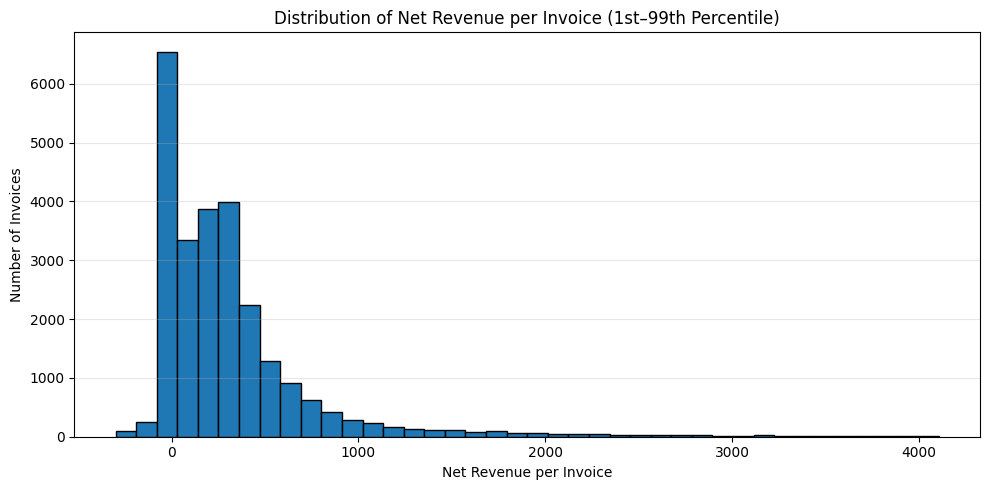

In [25]:
# Calculate the 1st and 99th percentiles
lower_limit = invoice_revenue["Net_Revenue"].quantile(0.01)
upper_limit = invoice_revenue["Net_Revenue"].quantile(0.99)

# Keep values within this range for the chart only
invoice_revenue_plot = invoice_revenue[
    invoice_revenue["Net_Revenue"].between(
        lower_limit, upper_limit
    )
]

# Plot the invoice revenue distribution
plt.figure(figsize=(10, 5))

plt.hist(
    invoice_revenue_plot["Net_Revenue"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Net Revenue per Invoice (1st–99th Percentile)")
plt.xlabel("Net Revenue per Invoice")
plt.ylabel("Number of Invoices")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Add the month to each invoice using its invoice date
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Count unique invoices in each month
monthly_invoices = (
    df.groupby("YearMonth")["InvoiceNo"]
    .nunique()
    .reset_index(name="Invoice_Count")
)

# Display monthly invoice counts
display(monthly_invoices)

,YearMonth,Invoice_Count
0,2010-12,2025
1,2011-01,1476
2,2011-02,1393
3,2011-03,1983
4,2011-04,1744
5,2011-05,2162
6,2011-06,2012
7,2011-07,1927
8,2011-08,1737
9,2011-09,2327


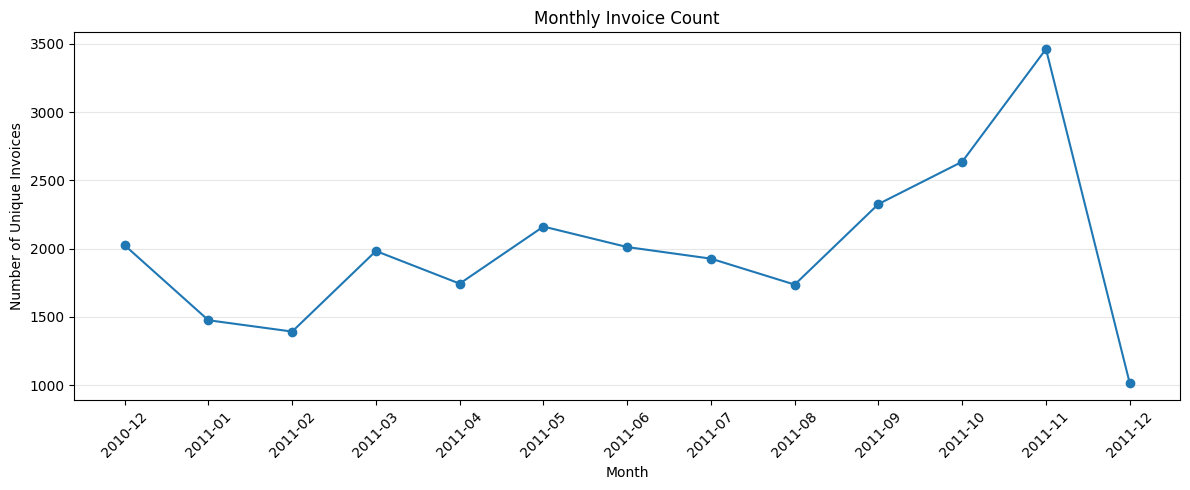

In [27]:
# Convert month labels to strings for plotting
monthly_invoices["YearMonth"] = monthly_invoices["YearMonth"].astype(str)

# Create a monthly invoice count chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_invoices["YearMonth"],
    monthly_invoices["Invoice_Count"],
    marker="o"
)

plt.title("Monthly Invoice Count")
plt.xlabel("Month")
plt.ylabel("Number of Unique Invoices")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Merge monthly revenue and invoice counts
monthly_comparison = pd.merge(
    monthly_revenue,
    monthly_invoices,
    on="YearMonth"
)

# Display both metrics side by side
display(monthly_comparison)

,YearMonth,Revenue,Invoice_Count
0,2010-12,746723.610,2025
1,2011-01,558448.560,1476
2,2011-02,497026.410,1393
3,2011-03,682013.980,1983
4,2011-04,492367.841,1744
5,2011-05,722094.100,2162
6,2011-06,689977.230,2012
7,2011-07,680156.991,1927
8,2011-08,681386.460,1737
9,2011-09,1017596.682,2327


In [29]:
# Calculate net revenue per invoice for each month
monthly_comparison["Net_Revenue_Per_Invoice"] = (
    monthly_comparison["Revenue"]
    / monthly_comparison["Invoice_Count"]
)

# Display the comparison
display(monthly_comparison)

,YearMonth,Revenue,Invoice_Count,Net_Revenue_Per_Invoice
0,2010-12,746723.610,2025,368.752400
1,2011-01,558448.560,1476,378.352683
2,2011-02,497026.410,1393,356.802879
3,2011-03,682013.980,1983,343.930398
4,2011-04,492367.841,1744,282.321010
5,2011-05,722094.100,2162,333.993571
6,2011-06,689977.230,2012,342.931029
7,2011-07,680156.991,1927,352.961594
8,2011-08,681386.460,1737,392.277755
9,2011-09,1017596.682,2327,437.299820


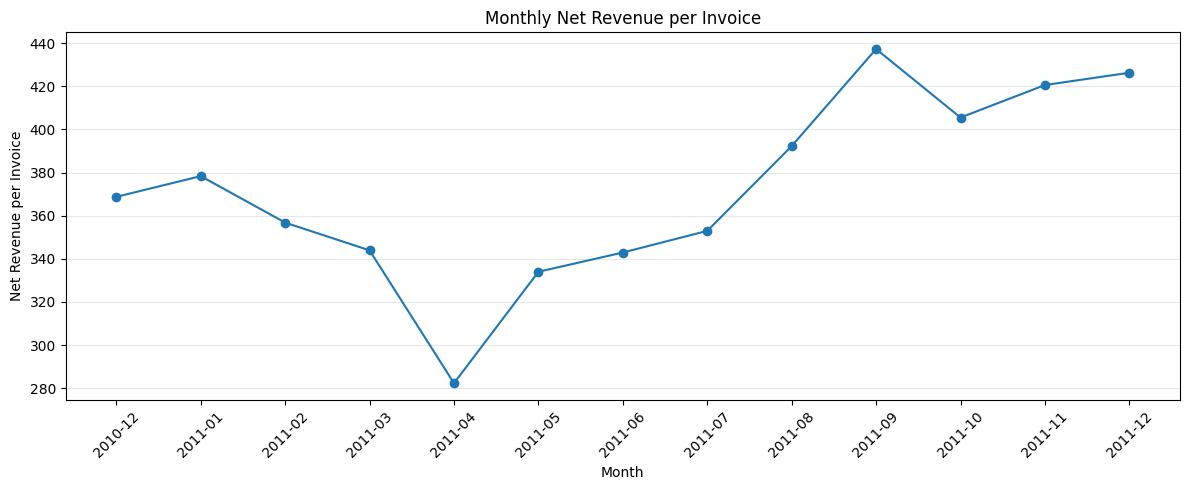

In [30]:
# Plot monthly net revenue per invoice
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_comparison["YearMonth"],
    monthly_comparison["Net_Revenue_Per_Invoice"],
    marker="o"
)

plt.title("Monthly Net Revenue per Invoice")
plt.xlabel("Month")
plt.ylabel("Net Revenue per Invoice")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# Count unique identifiable customers in each month
monthly_customers = (
    df.dropna(subset=["CustomerID"])
    .groupby("YearMonth")["CustomerID"]
    .nunique()
    .reset_index(name="Unique_Customers")
)

# Display monthly customer counts
display(monthly_customers)

,YearMonth,Unique_Customers
0,2010-12,948
1,2011-01,783
2,2011-02,798
3,2011-03,1020
4,2011-04,899
5,2011-05,1079
6,2011-06,1051
7,2011-07,993
8,2011-08,980
9,2011-09,1302


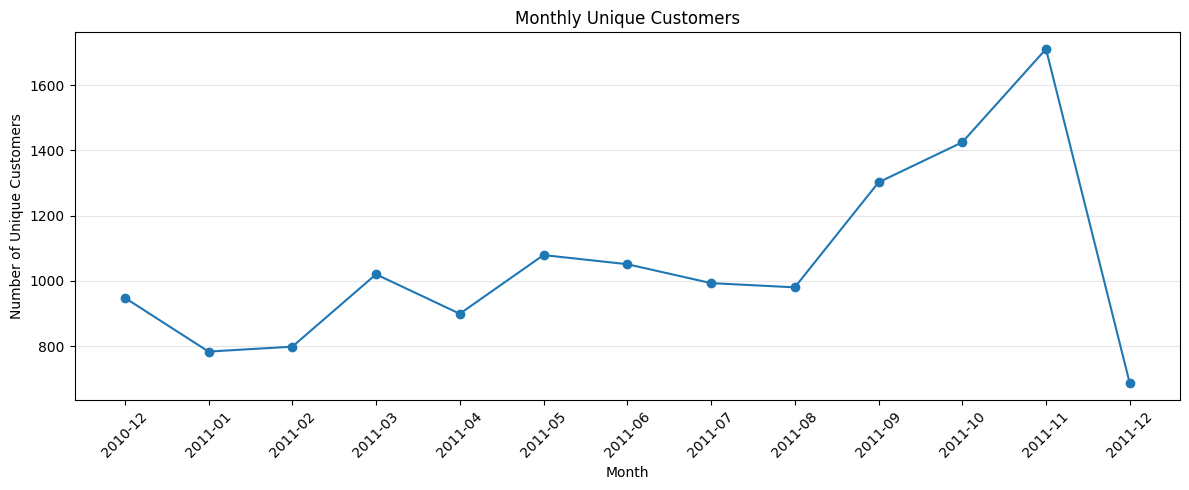

In [32]:
# Convert month labels to strings for plotting
monthly_customers["YearMonth"] = (
    monthly_customers["YearMonth"].astype(str)
)

# Plot unique customers by month
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_customers["YearMonth"],
    monthly_customers["Unique_Customers"],
    marker="o"
)

plt.title("Monthly Unique Customers")
plt.xlabel("Month")
plt.ylabel("Number of Unique Customers")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Count distinct invoices for each identifiable customer
customer_orders = (
    df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

# Count customers by number of invoices
print("Customers with 1 invoice:", (customer_orders == 1).sum())
print("Customers with more than 1 invoice:", (customer_orders > 1).sum())

# Display summary statistics
display(customer_orders.describe())

Customers with 1 invoice: 1313
Customers with more than 1 invoice: 3059


count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64

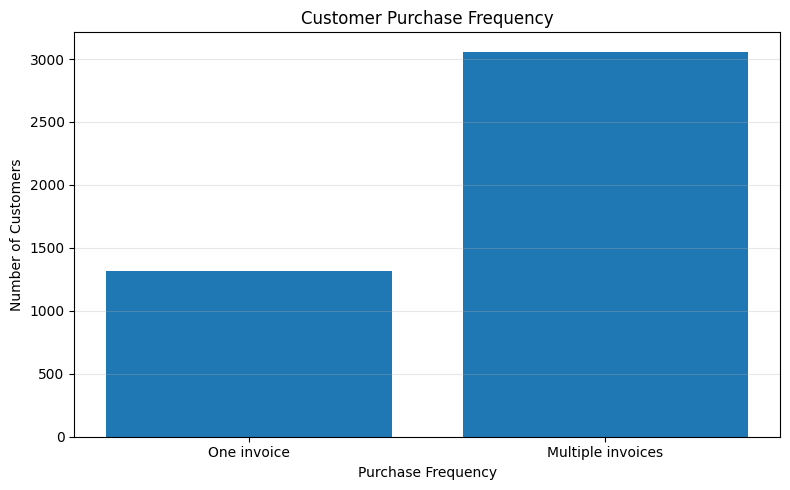

In [34]:
# Count customers in each purchase-frequency group
purchase_frequency = pd.Series({
    "One invoice": (customer_orders == 1).sum(),
    "Multiple invoices": (customer_orders > 1).sum()
})

# Create a bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    purchase_frequency.index,
    purchase_frequency.values
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Select the numerical columns for correlation analysis
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "Revenue"
]

# Calculate the correlation matrix
correlation_matrix = df[numeric_columns].corr()

# Display the results
display(correlation_matrix)

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.001241,0.886712
UnitPrice,-0.001241,1.000000,-0.162043
Revenue,0.886712,-0.162043,1.000000


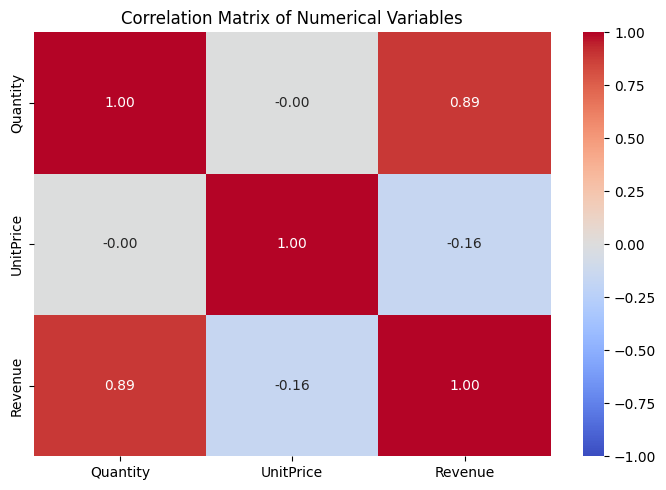

In [36]:
# Create a correlation heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

In [37]:
# Calculate the 1st and 99th revenue percentiles
lower_revenue = df["Revenue"].quantile(0.01)
upper_revenue = df["Revenue"].quantile(0.99)

# Count revenue values outside these limits
extreme_revenue_count = (
    (df["Revenue"] < lower_revenue) |
    (df["Revenue"] > upper_revenue)
).sum()

print(f"1st percentile: {lower_revenue:.2f}")
print(f"99th percentile: {upper_revenue:.2f}")
print("Rows outside percentile limits:", extreme_revenue_count)

# Display the rows with the highest absolute revenue
display(
    df.loc[df["Revenue"].abs().nlargest(5).index,
           ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "Revenue"]]
)

1st percentile: -6.62
99th percentile: 180.37
Rows outside percentile limits: 10734


,InvoiceNo,StockCode,Quantity,UnitPrice,Revenue
535160,581483,23843,80995,2.08,168469.6
535161,C581484,23843,-80995,2.08,-168469.6
61006,541431,23166,74215,1.04,77183.6
61011,C541433,23166,-74215,1.04,-77183.6
220825,556444,22502,60,649.50,38970.0


In [38]:
# Inspect the transaction with revenue of 38,970
display(
    df.loc[
        df["Revenue"] == 38970,
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country",
            "Revenue"
        ]
    ]
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
220825,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.5,15098,United Kingdom,38970.0


In [39]:
# Original dataset columns from Task 1
original_columns = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID",
    "Country",
    "ZeroPriceFlag",
    "NegativePriceFlag",
    "NegativeQuantityFlag",
    "Revenue",
    "HighQuantityFlag"
]

# Check the EDA dataset
print("Dataset shape:", df.shape)

# Check duplicates in the original columns
print(
    "Duplicate rows:",
    df.duplicated(subset=original_columns).sum()
)

# Check missing dates
print(
    "Missing invoice dates:",
    df["InvoiceDate"].isnull().sum()
)

# Validate revenue calculation
print(
    "Revenue calculation correct:",
    np.allclose(
        df["Revenue"],
        df["Quantity"] * df["UnitPrice"]
    )
)

# Check Saturday transaction rows
print(
    "Saturday transaction rows:",
    (df["DayOfWeek"] == "Saturday").sum()
)

Dataset shape: (536641, 15)
Duplicate rows: 0
Missing invoice dates: 0
Revenue calculation correct: True
Saturday transaction rows: 0
